
# Week 5: Compare our simulation with real outbreaks

Machine Learning and Data Science Club

Final assignment

Research question: How closely does our disease simulation match real outbreaks of measles, influenza, and COVID 19?

We already built the model in the earlier weeks. This week is only about comparing our saved simulation with real outbreak records.

You do not need to rebuild the town.
You do not need to redo the old graphs.
You do not need a separate CSV file.

This notebook already includes the numbers you need.



## What we are comparing

We are using 8 weeks of saved simulation results for each disease.

For the real world side, we use:

1. Measles in Texas
2. Influenza A laboratory reports in the United States
3. COVID 19 reported cases in the United States

Important note:
Our town has 100 people, but the real world data is much bigger.
So we are not comparing raw counts directly.
We are comparing the weekly pattern.

That means we care about questions like:

- When did the outbreak peak?
- Did it rise early or late?
- Did it fall quickly or slowly?
- Which disease did our model match best?


## Shared setup

Run this once. Do not change the data.

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from io import StringIO
from IPython.display import display

saved_results = """disease,week,model_new_infections,real_reported
measles,1,13,50
measles,2,17,68
measles,3,47,61
measles,4,17,68
measles,5,5,65
measles,6,0,84
measles,7,0,67
measles,8,0,67
influenza,1,24,6109
influenza,2,18,7711
influenza,3,12,9478
influenza,4,1,12074
influenza,5,0,12903
influenza,6,0,13287
influenza,7,0,12647
influenza,8,0,11622
covid_19,1,55,1373182
covid_19,2,44,2875294
covid_19,3,0,4975905
covid_19,4,0,5648740
covid_19,5,0,5035610
covid_19,6,0,3747626
covid_19,7,0,2106639
covid_19,8,0,1259908"""

data = pd.read_csv(StringIO(saved_results))

data["model_share"] = data.groupby("disease")["model_new_infections"].transform(lambda x: 100 * x / x.sum())
data["real_share"] = data.groupby("disease")["real_reported"].transform(lambda x: 100 * x / x.sum())

# These indices use week 1 of each real outbreak as the starting point (100).
# They do not use future weeks to decide their scale.
data["real_index"] = 100 * data["real_reported"] / data.groupby("disease")["real_reported"].transform("first")
data["model_index"] = 100 * data["model_new_infections"] / data.groupby("disease")["model_new_infections"].transform("first")

print("Data loaded for all three diseases.")
display(data[["disease", "week", "model_new_infections", "real_reported"]].head())



## Part 1: Alex

### Measles

Goal: Make one clear chart that compares our measles simulation with the real measles outbreak in Texas.

Steps

1. Select only the measles rows.
2. Make a chart with week on the x axis.
3. Plot `model_share` as one line.
4. Plot `real_share` as another line.
5. Add a title, axis labels, and legend.
6. Find the model peak week and the real peak week.
7. Add vertical lines for those peak weeks.
8. Print both peak weeks.

Use percentage share, not raw counts.
That keeps the comparison fair.


In [ ]:

measles = data[data["disease"] == "measles"].copy()

model_peak_week = None
real_peak_week = None

plt.figure(figsize=(8, 4))
# TODO: plot measles["week"] and measles["model_share"]
# TODO: plot measles["week"] and measles["real_share"]
# TODO: add plt.axvline(...) for the model peak week
# TODO: add plt.axvline(...) for the real peak week
# TODO: add title, x label, y label, legend, and tight layout
plt.show()

print("Model peak week:", model_peak_week)
print("Texas peak week:", real_peak_week)



Expected outcome

The two lines should not peak at the same time.
Our measles model should peak in week 3.
The Texas outbreak should peak in week 6.
The model should look earlier and sharper than the real outbreak.

Write two short sentences saying whether the model peaked too early and whether the overall shapes look similar.


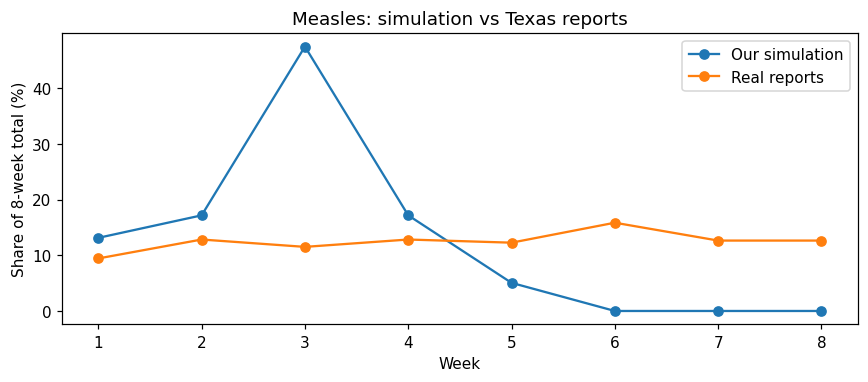


## Part 2: Linh

### Influenza A

Goal: Make one chart that compares our influenza simulation with real influenza A reports.

Steps

1. Select only the influenza rows.
2. Make a line chart of `model_share` and `real_share` by week.
3. Add a marker on the model peak week.
4. Add a marker on the real peak week.
5. Print the two peak weeks.
6. Calculate the correlation between `model_share` and `real_share`.
7. Print the correlation rounded to two decimals.

This tells us whether the two patterns moved together or in opposite directions.


In [ ]:

flu = data[data["disease"] == "influenza"].copy()

model_peak_week = None
real_peak_week = None
correlation = None

plt.figure(figsize=(8, 4))
# TODO: plot the model_share line
# TODO: plot the real_share line
# TODO: add scatter markers for the peak points
# TODO: add title, labels, legend, and tight layout
plt.show()

print("Model peak week:", model_peak_week)
print("CDC peak week:", real_peak_week)
print("Correlation:", correlation)



Expected outcome

The model should peak in week 1.
The real influenza reports should peak in week 6.
The correlation should be strongly negative, around -0.98.

That means our simulation moved in the opposite direction from the real influenza pattern during this 8 week window.


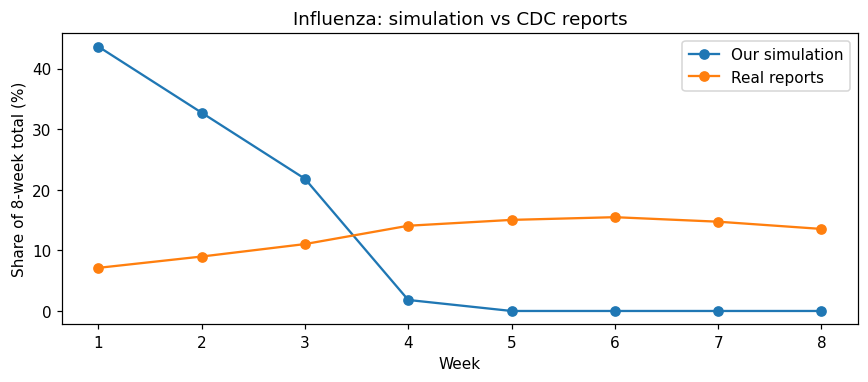


## Part 3: Aayush

### COVID 19

Goal: Make one chart that compares our COVID 19 simulation with real reported U.S. cases.

Steps

1. Select only the COVID 19 rows.
2. Plot `model_share` and `real_share` by week.
3. Find the model peak week and the real peak week.
4. Add vertical lines or markers for both peaks.
5. Find how much of the outbreak happened in the first four weeks for the model.
6. Find how much happened in the first four weeks for the real data.
7. Print both shares.

This helps us see whether the model spread too fast.


In [ ]:

covid = data[data["disease"] == "covid_19"].copy()
first_four = covid[covid["week"] <= 4]

model_peak_week = None
real_peak_week = None
model_early_share = None
real_early_share = None

plt.figure(figsize=(8, 4))
# TODO: plot model_share and real_share
# TODO: add vertical lines or scatter markers for both peaks
# TODO: add title, labels, legend, and tight layout
plt.show()

print("Model peak week:", model_peak_week)
print("Real peak week:", real_peak_week)
print("Model share in first 4 weeks:", model_early_share)
print("Real case share in first 4 weeks:", real_early_share)



Expected outcome

The model should peak in week 1.
The real outbreak should peak in week 4.
The model should place 100 percent of its outbreak in the first four weeks.
The real data should be closer to about 55 percent in the first four weeks.

That means the town simulation spread COVID 19 much faster than the real reported wave.


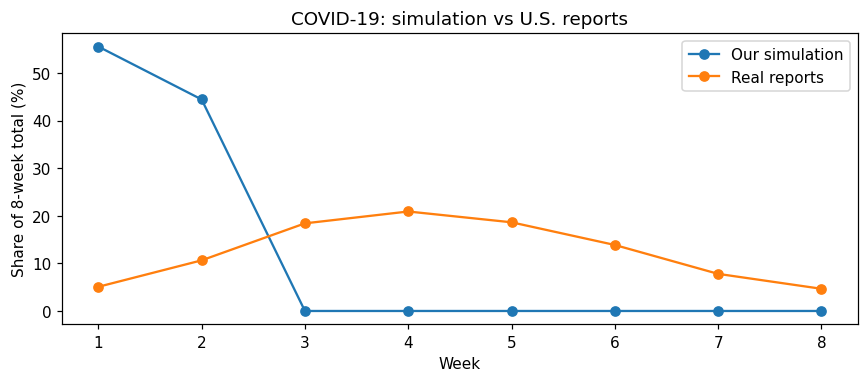

## Part 4: Ei Kay

### Machine learning 1: Linear Regression

Goal: Train a model using the simulation and real outbreak records. Then see how close its predictions are to the actual reports.

We will use all three diseases. Week 1 is set to 100 for each disease so we can compare how the reported numbers changed. We will train using weeks 1 to 6 and test on weeks 7 and 8. The last two weeks must not be used to train.

Steps

1. Import `LinearRegression` and `mean_absolute_error` from `sklearn`.
2. Use `pd.get_dummies()` on `disease`, `week`, and `model_index` to make the input table `X`.
3. Use `real_index` as the answer column `y`.
4. Select weeks 1 to 6 for training, and weeks 7 and 8 for testing.
5. Create `LinearRegression()` and use `.fit()` with the training inputs and answers.
6. Use `.predict()` on the testing inputs.
7. Calculate the Mean Absolute Error using `mean_absolute_error()`.
8. Make a bar chart comparing the real index and predicted index for the six test rows. Add a title and legend.

What it should look like: Two bars for each test result, one for the actual reports and one for the model prediction.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

X = pd.get_dummies(data[["disease", "week", "model_index"]], columns=["disease"], dtype=int)
y = data["real_index"]

train_rows = data["week"] <= 6
test_rows = data["week"] > 6

X_train = X[train_rows]
X_test = X[test_rows]
y_train = y[train_rows]
y_test = y[test_rows]

lr = LinearRegression()

# TODO: Train the model with lr.fit(X_train, y_train)
# TODO: Make predictions with lr.predict(X_test) and save as predictions
# TODO: Find the average error with mean_absolute_error(y_test, predictions)

# TODO: Make a results table containing disease, week, real value and prediction
# Hint: Use data.loc[test_rows, ["disease", "week"]].copy()

# TODO: Make a bar chart of actual and predicted values
# Hint: use .plot(kind="bar") on the two columns in your results table

# TODO: Print the mean absolute error rounded to one decimal place

Expected outcome

Your chart should have two bars for each disease in weeks 7 and 8. The bars will not be the same height.

Mean Absolute Error: about 138.8 index points.

Write two short sentences. Did the model make good predictions? Why is it difficult to learn from only six training weeks per disease?

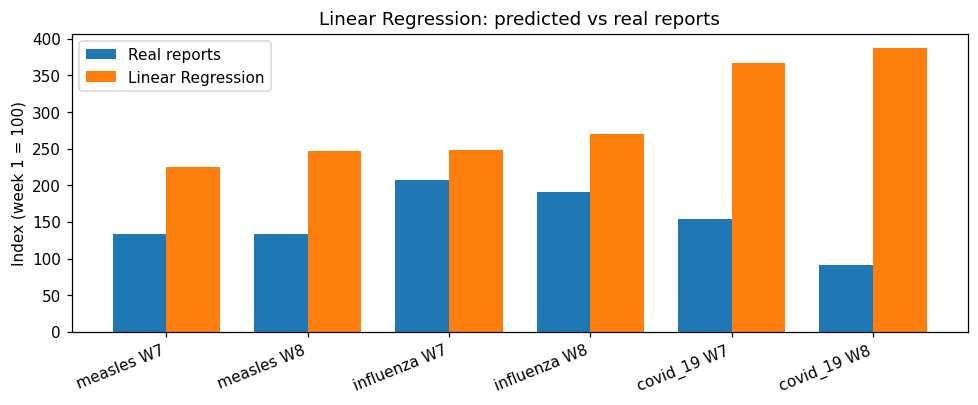

## Part 5: Jayden

### Machine learning 2: Decision Tree

Goal: Use a Decision Tree to guess whether real reports went up or down compared with the previous week.

We will use the same three diseases. A value of `1` means reports increased. A value of `0` means reports stayed the same or decreased.

Steps

1. Import `DecisionTreeClassifier`, `accuracy_score` and `plot_tree` from `sklearn`.
2. Make a column called `previous_reported` using `groupby("disease")["real_reported"].shift(1)`.
3. Make a column called `went_up` by checking whether `real_reported` is greater than `previous_reported`. Turn True and False into 1 and 0 with `.astype(int)`.
4. Use weeks 2 to 6 to train. Use weeks 7 and 8 to test. We skip week 1 because it has no earlier week.
5. Use the same input columns as Part 4: `disease`, `week`, and `model_index`.
6. Create `DecisionTreeClassifier(max_depth=3, random_state=42)`.
7. Train it with `.fit()` and predict the test results with `.predict()`.
8. Calculate accuracy with `accuracy_score()`.
9. Use `plot_tree()` to draw the decision tree. Give it feature names and class names.
10. Use `ConfusionMatrixDisplay.from_predictions()` to show which test results the model got right or wrong.

What it should look like: A tree with yes or no questions, followed by a small confusion matrix picture.

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

ml_data = data.copy()

# TODO: Make the previous_reported column with groupby() and shift(1)
# TODO: Make went_up = 1 when real_reported > previous_reported, otherwise 0

# Skip the first week for each disease
ml_data = ml_data[ml_data["week"] >= 2].copy()

X = pd.get_dummies(ml_data[["disease", "week", "model_index"]], columns=["disease"], dtype=int)

# TODO: Set y equal to the went_up column
train_rows = ml_data["week"] <= 6
test_rows = ml_data["week"] > 6

# TODO: Make X_train, X_test, y_train, and y_test

# TODO: Create DecisionTreeClassifier(max_depth=3, random_state=42)
# TODO: Train the tree with .fit()
# TODO: Predict the test labels with .predict()
# TODO: Print accuracy using accuracy_score(y_test, predictions)

# TODO: Draw the tree using plot_tree(model, feature_names=X.columns, class_names=["Not up", "Up"], filled=True)
# TODO: Draw the confusion matrix using ConfusionMatrixDisplay.from_predictions(y_test, predictions)

Expected outcome

You should see a Decision Tree picture and a confusion matrix. Your test accuracy should be about 33%. The test has only six rows, so this score is not enough to claim the model predicts real outbreaks.

Write two short sentences. Did the tree get most weeks right? Does this small test prove it will work on a new outbreak?

Run `plot_tree()` in Part 5 to see the decision tree diagram.

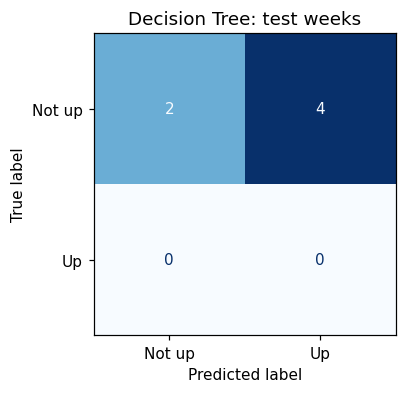

## Final questions

Answer in a short paragraph after the five coding parts are complete.

1. Did our simulated outbreaks peak at the same time as the real reports?
2. What did Linear Regression predict well or poorly?
3. What did the Decision Tree get right or wrong?
4. What is one limitation of comparing a town of 100 people with real outbreaks?
5. What would you improve before testing the model on another outbreak?

Remember: We are studying three real historical outbreak records, but the town results are simulations. The historical windows were chosen separately and the model does not use the actual population, contacts, immunity or reporting rules in those places. With only eight weeks per disease, these machine learning results are a practice exercise, not a validated forecasting system.

Sources: [Texas measles records](https://github.com/CSSEGISandData/measles_data/blob/main/Top_states_time_series.csv), [CDC influenza A surveillance](https://www.cdc.gov/flu/weekly/weeklyarchives2019-2020/data/whoAllregt_cl19.html), [Johns Hopkins COVID-19 reports](https://github.com/CSSEGISandData/COVID-19/blob/master/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_confirmed_global.csv).